In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["VECLIB_MAXIMUM_THREADS"] = "1"
os.environ["NUMEXPR_NUM_THREADS"] = "1"

os.environ["NUMBA_THREADING_LAYER"] = "tbb"

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import RegularGridInterpolator, griddata, interp1d
import cartopy.crs as ccrs
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import matplotlib.ticker as mticker
import matplotlib.colors as colors
from matplotlib.cm import ScalarMappable
import gc

import cmocean
from netCDF4 import Dataset
#from datetime import date, timedelta
import xarray as xr
## . . For animation
from matplotlib import animation
from IPython.display import HTML, Image
import geopandas
import rioxarray as rio
from shapely.geometry import mapping, shape
import pandas as pd
from pyproj import Transformer
from numba import jit
import time

# TDMA Model

In [3]:
@jit(nopython=True)
def TDMA(ac,bc,cc,dc):
        #a : left coefficients (i-1)
        #b : center coefficients (i)
        #c : right coefficients (i+1)
        #d : right hand vector 
        #xc : solution at t+1

        #a,b,c,d exclude the top grid point (head is set by hydrostatic ice pressure)

        nf = len(dc) #number of equations

        #Forward Sweep
        for it in range(1,nf):
            mc = ac[it]/bc[it-1]
            bc[it] = bc[it] - mc*cc[it-1] #Overwrites bc
            dc[it] = dc[it] - mc*dc[it-1] #overwrites d

        #Backsubstitution sweep
        xc = np.empty(nf, dtype=np.float64)
        xc[-1] = dc[-1]/bc[-1]

        for il in range(nf-2,-1,-1):
            xc[il] = (dc[il] - cc[il]*xc[il+1])/bc[il]
        return xc

@jit(nopython=True)
def solve_diffusion(h,C_D,Svec,TB_k,TB_knext):
        #h : head at time t
        #C_D : diffusion coefficient = D*dt/dz**2
        n = len(h)
        #Set up coefficients
        aa = -0.5*C_D*np.ones(n-1, dtype=np.float64)
        bb = (1+C_D)*np.ones(n-1, dtype=np.float64)
        cc = -0.5*C_D*np.ones(n-1, dtype=np.float64)

        #Set up rhs solution
        dd = np.zeros(n-1, dtype=np.float64)
        dd[1:-1] = 0.5*C_D*h[3:] + (1-C_D)*h[2:-1] + 0.5*C_D*h[1:-2] + Svec[2:-1]
        #Top Boundary Condition
        dd[0] = 0.5*C_D*h[2] + (1-C_D)*h[1] + 0.5*C_D*(TB_k + TB_knext)+ Svec[1]


        #Bottom Boundary Condition
        dd[-1] = (1-C_D)*h[-1] + C_D*h[-2] + Svec[-1]
        aa[-1] = -C_D

        # Call Solver
        h[1:] = TDMA(aa,bb,cc,dd)

        return h


@jit(nopython=True, parallel=False)
def run_model(intSave,xi,perm,S,dt,dz,L,nt,dhdt,thk):

    rhoi = 920
    rhow = 1000
    g = 9.81
    mu_w = 1e-3

    K_t = perm*rhow*g/mu_w
    D = K_t/S
    
    nz = int(L/dz) + 1
    n_save = int(nt/intSave)

    h = np.ones(nz, dtype=np.float64)
    h_all = np.zeros((nz,n_save), dtype=np.float64)
    Svec = np.zeros(nz, dtype=np.float64)

    C_D = D*dt/(dz*dz)

    #Initial head condition is scaled to ratio of ice to water densities
    hm = thk*(rhoi/rhow)*h
    h_all[:,0] = hm
    thk_m = thk
    for k in range(nt):
        dhdt_t = dhdt[k]
        TB_k = (rhoi/rhow)*thk_m
        TB_knext = (rhoi/rhow)*(thk_m + dt*dhdt_t)
        hm[0] = TB_k
        Svec[:] = dt*xi*(rhoi/rhow)*dhdt_t
        hm = solve_diffusion(hm,C_D,Svec,TB_k,TB_knext)
        hm[0] = TB_knext
        thk_m = thk_m + dt*dhdt_t # Adds dh due to instantaneous dhdt*dt in m

        if k%intSave == 0:
            h_all[:,int(k/intSave)] = hm
    
    sfc = K_t*(h_all[0,:]-h_all[1,:])/dz 
        
    return sfc,h_all

# Base parameters
xi = 0.2 \
k = $10^{-13} m^2$ \
S = $10^{-6} m^{-1}$ \
L = 3km 

Unloading for 1 year (-10m/yr thinning) then drainage (0 m/yr) for 1 years \
Initial Ice Thickness of 1000 m

In [4]:
intSave=1
year = 3600*24*365.25
dt = 2*3600 
tf = year*20 # 10 years
nt = int(np.round(tf / dt)+1)
dz = 100
thk_init = 1e3
max_nz = int(400e3/dz)+1
rhoi = 920
rhow = 1000
g = 9.81
mu_w = 1e-3
L_arr = [300,1e3,5e3,10e3,50e3,400e3]
k_arr = [1e-13,1e-14,1e-15,1e-16,1e-17]
S_arr = [1e-4,1e-5,1e-6,1e-7]
xi_arr = [0.0,0.2,0.5,0.8,1.0]

qf_L = np.zeros((nt,np.size(L_arr)))
qf_xi = np.zeros((nt,np.size(xi_arr)))
qf_S = np.zeros((nt,np.size(S_arr)))
qf_k = np.zeros((nt,np.size(k_arr)))

h_L = np.zeros((max_nz,nt,np.size(L_arr)))
h_xi = np.zeros((max_nz,nt,np.size(xi_arr)))
h_S = np.zeros((max_nz,nt,np.size(S_arr)))
h_k = np.zeros((max_nz,nt,np.size(k_arr)))

In [ ]:
# model_dates = np.arange(0,3653,0.5)
# nt

7306

In [ ]:
#nt*dt/(3600*24*365.25)

10.001368925393566

In [5]:
def forcing(ftype):
    thk_forcing = np.zeros(nt)
    dhdt_forcing = np.zeros(nt)
    thk_forcing[0] = 1e3 #Initial ice thickness
    dhdt_1 = -5/year
    dhdt_2 = -dhdt_1
    t_change_ind = int(nt/2)
    model_dates = np.arange(0,3653,0.5)

    if ftype == "step":
        dhdt_forcing[:t_change_ind] = dhdt_1
        dhdt_forcing[t_change_ind:] = dhdt_2

        for t in range(1,nt):
            thk_forcing[t] = thk_forcing[t-1] + dt*dhdt_forcing[t]
    elif ftype == "linear decrease":
        dhdt_forcing[:t_change_ind] = np.linspace(dhdt_1, 0, t_change_ind)
        dhdt_forcing[t_change_ind:] = dhdt_2
        for t in range(1,nt):
            thk_forcing[t] = thk_forcing[t-1] + dt*dhdt_forcing[t]
    elif ftype == "linear increase":
        dhdt_forcing[:t_change_ind] = np.linspace(0, dhdt_1, t_change_ind)
        dhdt_forcing[t_change_ind:] = dhdt_2
        for t in range(1,nt):
            thk_forcing[t] = thk_forcing[t-1] + dt*dhdt_forcing[t]
    elif ftype == "triangle":
        dhdt_forcing[:t_change_ind] = np.linspace(0, dhdt_1, t_change_ind)
        dhdt_forcing[t_change_ind:] = np.linspace(dhdt_1, 0, t_change_ind)
        for t in range(1,nt):
            thk_forcing[t] = thk_forcing[t-1] + dt*dhdt_forcing[t]
    elif ftype == "exp":
        tau = model_dates[t_change_ind - 1]
        t = model_dates[:t_change_ind]
        dhdt_forcing[:t_change_ind] = dhdt_1 * (1 - np.exp(-t / tau))
        for t in range(1,nt):
            thk_forcing[t] = thk_forcing[t-1] + dt*dhdt_forcing[t]

    return dhdt_forcing,thk_forcing

In [6]:
model_dates = np.linspace(0,20,nt)

In [7]:
dhdt_forcing,thk_forcing = forcing("step")

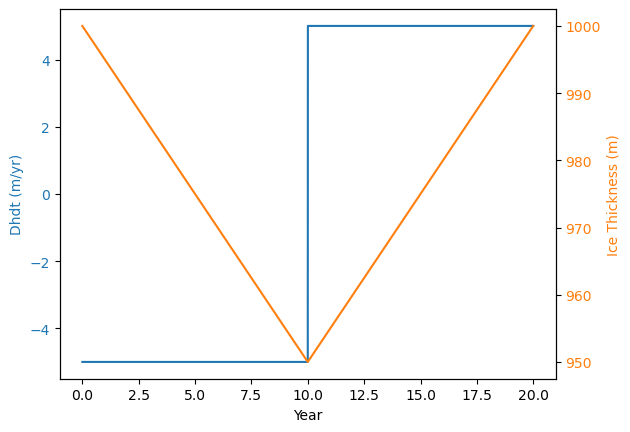

In [8]:
plt.figure()
ax = plt.gca()
ax2 = ax.twinx()
ax.plot(model_dates, dhdt_forcing*year, color = "C0")
ax2.plot(model_dates, thk_forcing, color="C1")

ax.set_xlabel("Year")
ax.set_ylabel("Dhdt (m/yr)", color = "C0")
ax.tick_params(axis="y", labelcolor="C0")

ax2.set_ylabel("Ice Thickness (m)", color = "C1")
ax2.tick_params(axis="y", labelcolor="C1")
#ax2.set_ylim([940, 1000])

In [15]:
for i in range(np.size(L_arr)):
    L_m = L_arr[i]
    xi = 0.2
    S = 1e-6
    k = 1e-13
    nz = int(L_m/dz)+1


    qf,h = run_model(intSave,xi,k,S,dt,dz,L_m,nt,dhdt_forcing,thk_init)
    qf_L[:,i] = qf
    h_L[:nz,:,i] = h

for i in range(np.size(xi_arr)):
    L_m = 400e3
    xi = xi_arr[i]
    S = 1e-6
    k = 1e-13
    nz = int(L_m/dz)+1

    qf,h = run_model(intSave,xi,k,S,dt,dz,L_m,nt,dhdt_forcing,thk_init)
    qf_xi[:,i] = qf
    h_xi[:nz,:,i] = h

for i in range(np.size(S_arr)):
    L_m = 400e3
    xi = 0.2
    S = S_arr[i]
    k = 1e-13
    nz = int(L_m/dz)+1


    qf,h = run_model(intSave,xi,k,S,dt,dz,L_m,nt,dhdt_forcing,thk_init)
    qf_S[:,i] = qf
    h_S[:nz,:,i] = h

for i in range(np.size(k_arr)):
    L_m = 400e3
    xi = 0.2
    S = 1e-6
    k = k_arr[i]
    nz = int(L_m/dz)+1


    qf,h = run_model(intSave,xi,k,S,dt,dz,L_m,nt,dhdt_forcing,thk_init)
    qf_k[:,i] = qf
    h_k[:nz,:,i] = h

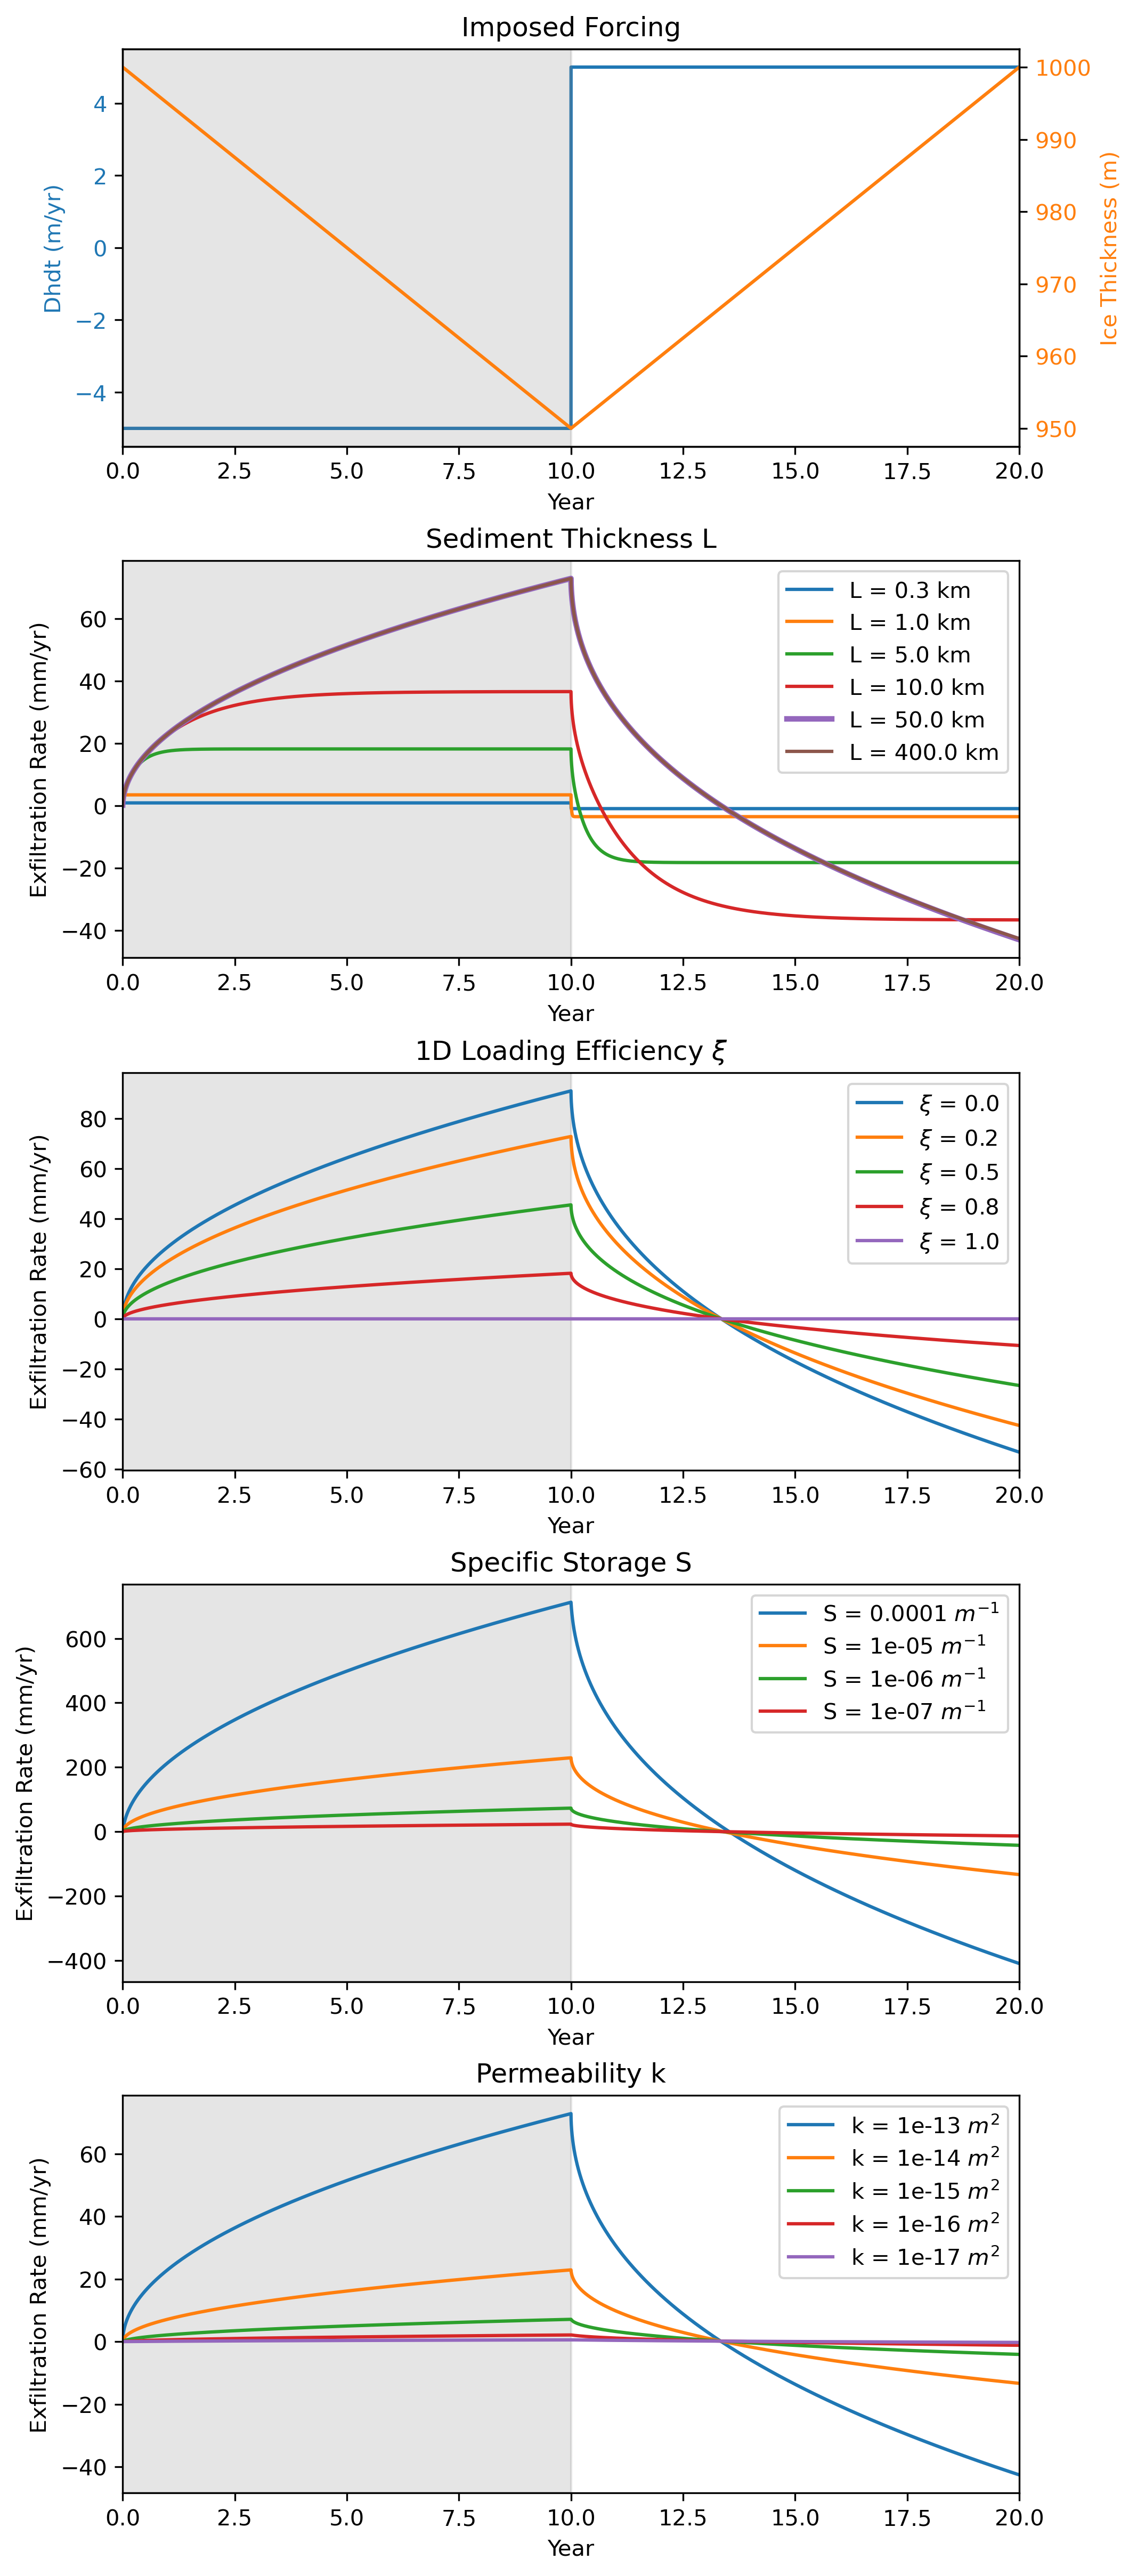

In [25]:
plt.figure(figsize=(7,16),dpi=300, layout='constrained')
ax = plt.subplot(5,1,1,title="Imposed Forcing")
ax1 = ax.twinx()
ax.plot(model_dates, dhdt_forcing*year, color = "C0")
ax1.plot(model_dates, thk_forcing, color="C1")
ax1.axvspan(0, 10, color='gray', alpha=0.2)

ax.set_xlabel("Year")
ax.set_ylabel("Dhdt (m/yr)", color = "C0")
ax.tick_params(axis="y", labelcolor="C0")

ax1.set_ylabel("Ice Thickness (m)", color = "C1")
ax1.tick_params(axis="y", labelcolor="C1")
#ax1.set_ylim([950, 1000])
plt.xlim([0,20])

ax2 = plt.subplot(5,1,2,title="Sediment Thickness L")
for i in range(np.size(L_arr)):
    if i == 4:
        lwsize = 2.5
    else:
        lwsize = 1.5
    ax2.plot(model_dates,-1000*year*qf_L[:,i],lw = lwsize,label="L = "+str(L_arr[i]/1000)+" km")
plt.legend(loc="upper right")
plt.xlabel("Year")
plt.ylabel("Exfiltration Rate (mm/yr)")
plt.xlim([0,20])
ax2.axvspan(0, 10, color='gray', alpha=0.2)


ax3 = plt.subplot(5,1,3,title=r"1D Loading Efficiency $\xi$")
for i in range(np.size(xi_arr)):
    ax3.plot(model_dates,-1000*year*qf_xi[:,i],label=r"$\xi$ = "+str(xi_arr[i]))
plt.legend(loc="upper right")
plt.xlabel("Year")
plt.ylabel("Exfiltration Rate (mm/yr)")
plt.xlim([0,20])
#plt.ylim([-2,2])
ax3.axvspan(0, 10, color='gray', alpha=0.2)


ax4 = plt.subplot(5,1,4,title="Specific Storage S")
for i in range(np.size(S_arr)):
    ax4.plot(model_dates,-1000*year*qf_S[:,i],label="S = "+str(S_arr[i])+r" $m^{-1}$")
plt.legend(loc="upper right")
plt.xlabel("Year")
plt.ylabel("Exfiltration Rate (mm/yr)")
plt.xlim([0,20])
ax4.axvspan(0, 10, color='gray', alpha=0.2)

ax5 = plt.subplot(5,1,5,title="Permeability k")
for i in range(np.size(k_arr)):
    ax5.plot(model_dates,-1000*year*qf_k[:,i],label="k = "+str(k_arr[i])+r" $m^2$")
plt.legend(loc="upper right")
plt.xlabel("Year")
plt.ylabel("Exfiltration Rate (mm/yr)")
plt.xlim([0,20])
ax5.axvspan(0, 10, color='gray', alpha=0.2)

